# Spanish headline retrieval: frozen benchmark analysis

## 1. Problem statement
How do lexical and pretrained representations compare for Spanish headline retrieval? This notebook analyzes frozen measurements; it does not rerun encoders, tune parameters or infer relevance.

## 2. Academic origin and audit finding
The original exercise used mutable model/tokenizer globals. Its visible flow generated BETO-labeled queries after loading Robertuito, causing a cross-encoder comparison on a sequential run. Matching vector dimensions did not make the spaces compatible. Missing historical executions prevent reconstructing every saved output. The portfolio rebuild uses owned encoders and identity checks; original comparative claims are not reused.

## 3. Dataset
DReggio/esg-spanish-events gold train/dev/test: 1,688 source rows, 1,625 normalized unique headlines. Stable event IDs and provenance are preserved. The publisher indicates CC BY-NC 4.0; [source](https://huggingface.co/datasets/DReggio/esg-spanish-events). Code and data are separate works. This notebook reads no raw headlines or archival files.

In [1]:
from pathlib import Path
import json, sys
from IPython.display import display, Markdown
ROOT = Path.cwd()
if not (ROOT / "evaluation/benchmark_results.json").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "scripts"))
from render_figures import plot_metric
results = json.loads((ROOT / "evaluation/benchmark_results.json").read_text(encoding="utf-8"))
assert results["metadata"]["corpus_size"] == 1625
assert results["metadata"]["query_count"] == 15
assert results["metadata"]["positive_judgments"] == 43


## 4. Retrieval systems
TF-IDF uses corpus-fitted unigram vocabulary and cosine. BETO and Robertuito each use first-token (historical baseline) and attention-mask-aware mean pooling (ablation). Attended special tokens are included. MiniLM uses SentenceTransformer.encode() and its pretrained pipeline. BETO and Robertuito are not presented as sentence-embedding models. Dense configurations: CPU, batch 32, maximum 128 tokens, L2 normalization; model commits are recorded in the public JSON. Robertuito does not add tweet preprocessing.

## 5. Evaluation methodology
The 15 queries were frozen before seeing model outputs. Each of six systems supplied top 10; union and deterministic shuffling produced 648 unique query-document pairs. Human judging hid model identity, score and rank. There are 43 positives; other pooled candidates are binary zero, outside-pool documents remain unjudged. Precision@5 and RR@10 are macro-averaged across all 15 queries. No unrestricted MRR or full-corpus recall is supported.

## 6. Official aggregate results
Runtime includes loading, corpus encoding, query retrieval and scoring on CPU.

In [2]:
labels = {'tfidf': 'TF-IDF', 'beto_first_token': 'BETO first-token', 'beto_masked_mean': 'BETO masked mean', 'robertuito_first_token': 'Robertuito first-token', 'robertuito_masked_mean': 'Robertuito masked mean', 'minilm': 'MiniLM'}
lines = ["| System | Precision@5 | MRR@10 | Runtime (s) |", "| --- | ---: | ---: | ---: |"]
for s in results["systems"]:
    lines.append(f"| {labels[s['system']]} | {s['precision_at_5']:.4f} | {s['mrr_at_10']:.4f} | {s['seconds']:.2f} |")
display(Markdown("\n".join(lines)))


| System | Precision@5 | MRR@10 | Runtime (s) |
| --- | ---: | ---: | ---: |
| TF-IDF | 0.1467 | 0.3889 | 1.23 |
| BETO first-token | 0.0133 | 0.0400 | 58.77 |
| BETO masked mean | 0.2400 | 0.4411 | 52.49 |
| Robertuito first-token | 0.0800 | 0.2169 | 52.87 |
| Robertuito masked mean | 0.2933 | 0.5833 | 53.46 |
| MiniLM | 0.2667 | 0.5278 | 14.24 |

## 7. Per-query analysis
Each cell is Precision@5 / RR@10. All 15 queries are retained. q05 illustrates MiniLM coverage; q09 favors BETO mean on this need; q10 shows a tie between the lexical baseline and two dense systems.

In [3]:
lines = ["| Query | " + " | ".join(labels[s["system"]] for s in results["systems"]) + " |", "| --- | " + " | ".join(["---:"] * 6) + " |"]
for i in range(15):
    values = [f"{s['per_query'][i]['precision_at_5']:.4f} / {s['per_query'][i]['reciprocal_rank_at_10']:.4f}" for s in results["systems"]]
    lines.append(f"| q{i+1:02d} | " + " | ".join(values) + " |")
display(Markdown("\n".join(lines)))


| Query | tfidf | beto_first_token | beto_masked_mean | robertuito_first_token | robertuito_masked_mean | minilm |
| --- | ---: | ---: | ---: | ---: | ---: | ---: |
| q01 | 0.2000 / 0.2500 | 0.0000 / 0.0000 | 0.4000 / 0.2500 | 0.0000 / 0.0000 | 0.2000 / 0.3333 | 0.0000 / 0.1667 |
| q02 | 0.6000 / 1.0000 | 0.0000 / 0.0000 | 0.6000 / 0.5000 | 0.0000 / 0.0000 | 0.6000 / 1.0000 | 0.8000 / 1.0000 |
| q03 | 0.2000 / 1.0000 | 0.0000 / 0.1000 | 0.2000 / 0.3333 | 0.0000 / 0.1429 | 0.6000 / 0.3333 | 0.4000 / 0.5000 |
| q04 | 0.0000 / 0.0000 | 0.0000 / 0.0000 | 0.4000 / 0.5000 | 0.0000 / 0.0000 | 0.2000 / 0.5000 | 0.2000 / 1.0000 |
| q05 | 0.0000 / 0.0000 | 0.0000 / 0.0000 | 0.0000 / 0.0000 | 0.0000 / 0.0000 | 0.0000 / 0.0000 | 0.4000 / 0.5000 |
| q06 | 0.2000 / 1.0000 | 0.0000 / 0.0000 | 0.2000 / 1.0000 | 0.0000 / 0.0000 | 0.2000 / 1.0000 | 0.2000 / 0.5000 |
| q07 | 0.2000 / 0.3333 | 0.0000 / 0.0000 | 0.0000 / 0.0000 | 0.0000 / 0.0000 | 0.0000 / 0.0000 | 0.0000 / 0.1667 |
| q08 | 0.0000 / 0.0000 | 0.2000 / 0.5000 | 0.2000 / 0.3333 | 0.0000 / 0.0000 | 0.2000 / 0.2500 | 0.2000 / 0.5000 |
| q09 | 0.0000 / 0.0000 | 0.0000 / 0.0000 | 0.6000 / 1.0000 | 0.0000 / 0.0000 | 0.4000 / 0.3333 | 0.0000 / 0.0000 |
| q10 | 0.4000 / 1.0000 | 0.0000 / 0.0000 | 0.2000 / 0.5000 | 0.2000 / 1.0000 | 0.4000 / 1.0000 | 0.4000 / 1.0000 |
| q11 | 0.2000 / 0.2500 | 0.0000 / 0.0000 | 0.4000 / 1.0000 | 0.4000 / 1.0000 | 0.4000 / 1.0000 | 0.2000 / 1.0000 |
| q12 | 0.0000 / 0.0000 | 0.0000 / 0.0000 | 0.2000 / 1.0000 | 0.0000 / 0.0000 | 0.2000 / 1.0000 | 0.2000 / 0.3333 |
| q13 | 0.2000 / 1.0000 | 0.0000 / 0.0000 | 0.0000 / 0.0000 | 0.0000 / 0.0000 | 0.0000 / 0.0000 | 0.4000 / 0.5000 |
| q14 | 0.0000 / 0.0000 | 0.0000 / 0.0000 | 0.2000 / 0.2000 | 0.0000 / 0.1111 | 0.2000 / 1.0000 | 0.2000 / 0.5000 |
| q15 | 0.0000 / 0.0000 | 0.0000 / 0.0000 | 0.0000 / 0.0000 | 0.6000 / 1.0000 | 0.8000 / 1.0000 | 0.4000 / 0.2500 |

## 8. Visualizations
Metric axes span 0–1; runtime starts at zero. All systems use the same color to avoid implying a preferred model.

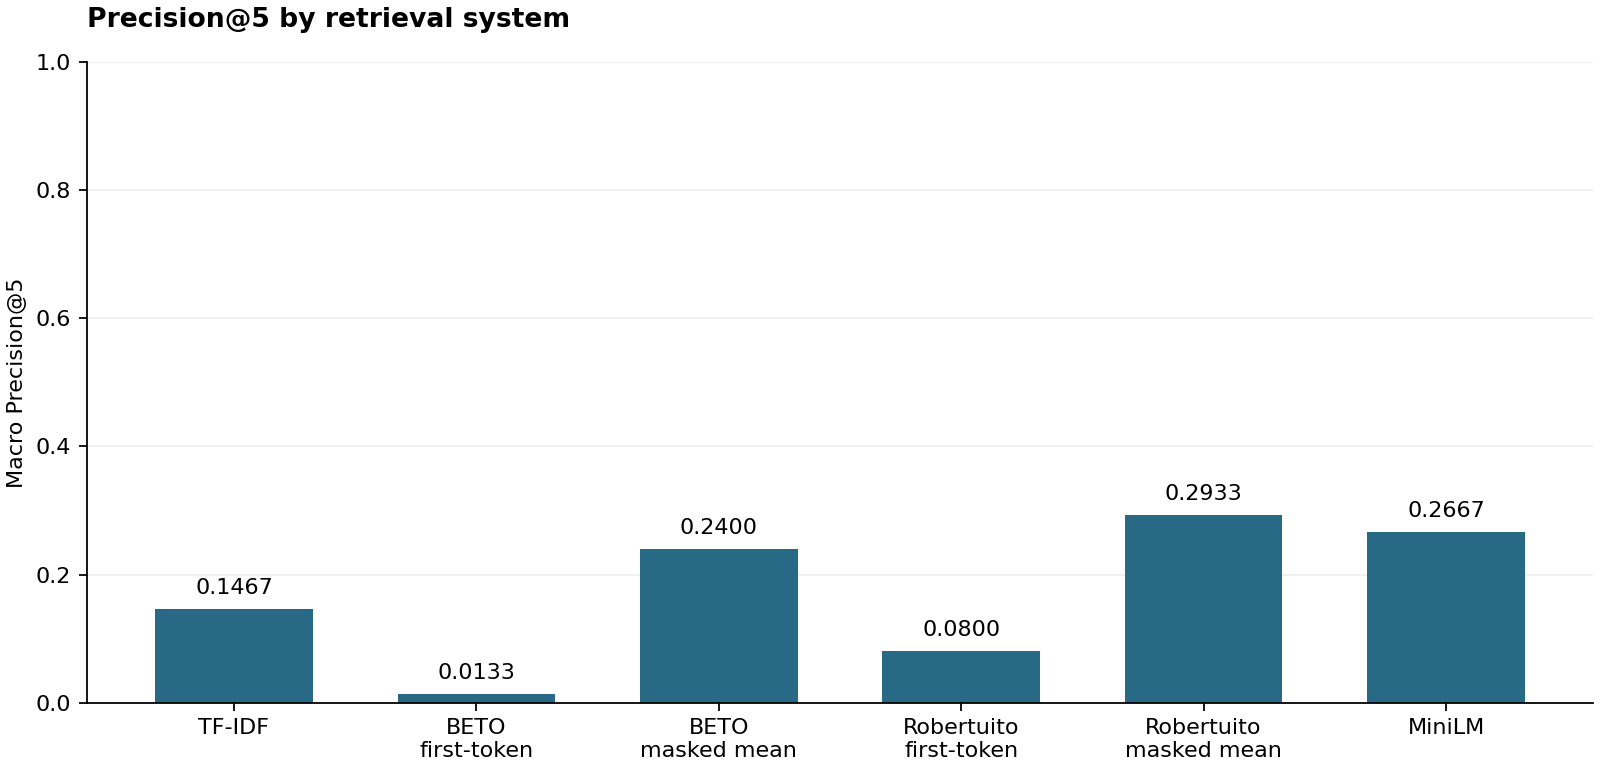

In [4]:
fig = plot_metric(results, 'precision_at_5', 'Precision@5 by retrieval system', 'Macro Precision@5', upper=1)
display(fig)
import matplotlib.pyplot as plt
plt.close(fig)


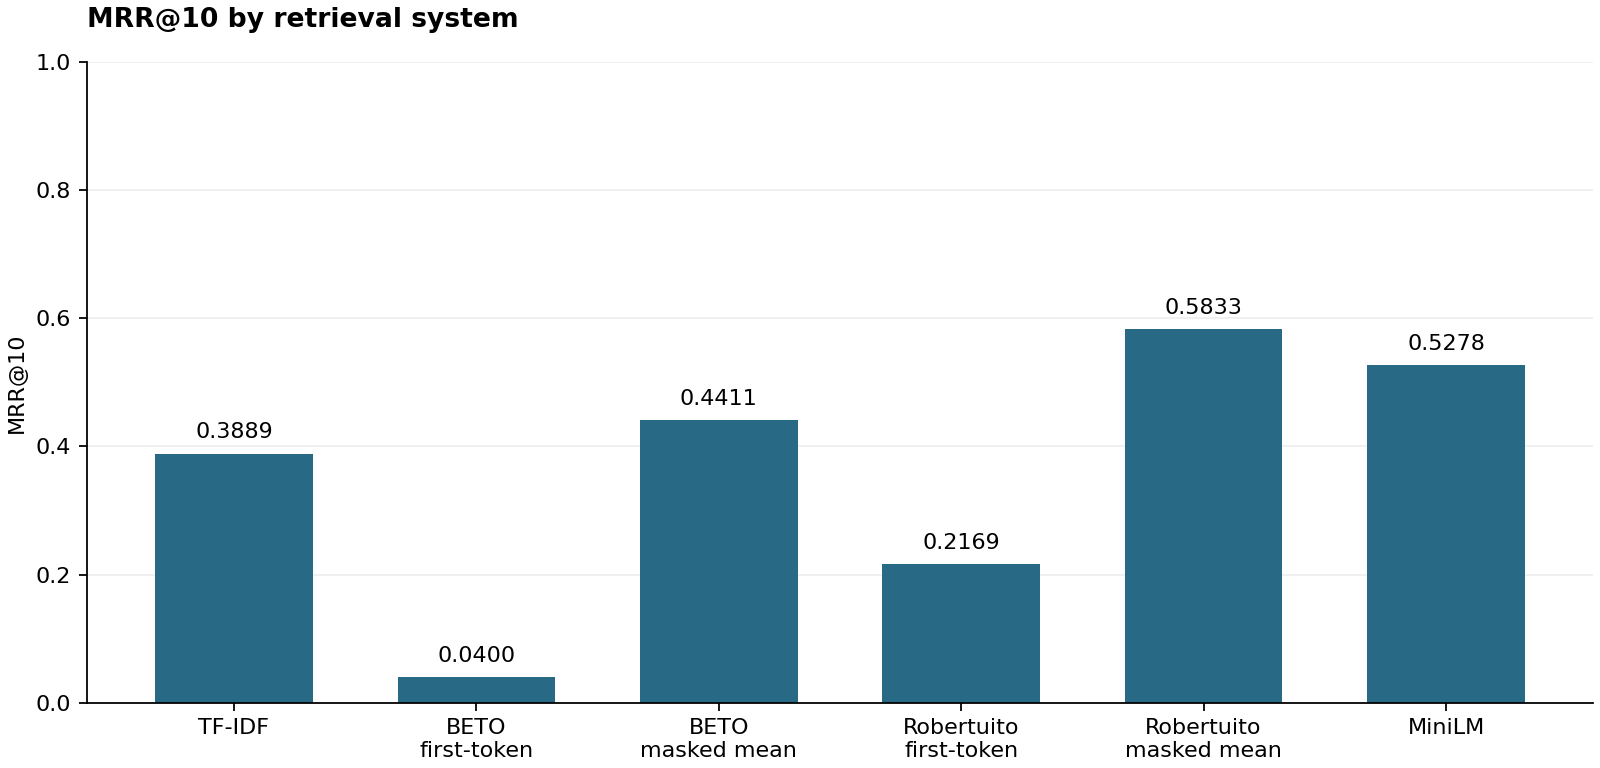

In [5]:
fig = plot_metric(results, 'mrr_at_10', 'MRR@10 by retrieval system', 'MRR@10', upper=1)
display(fig)
import matplotlib.pyplot as plt
plt.close(fig)


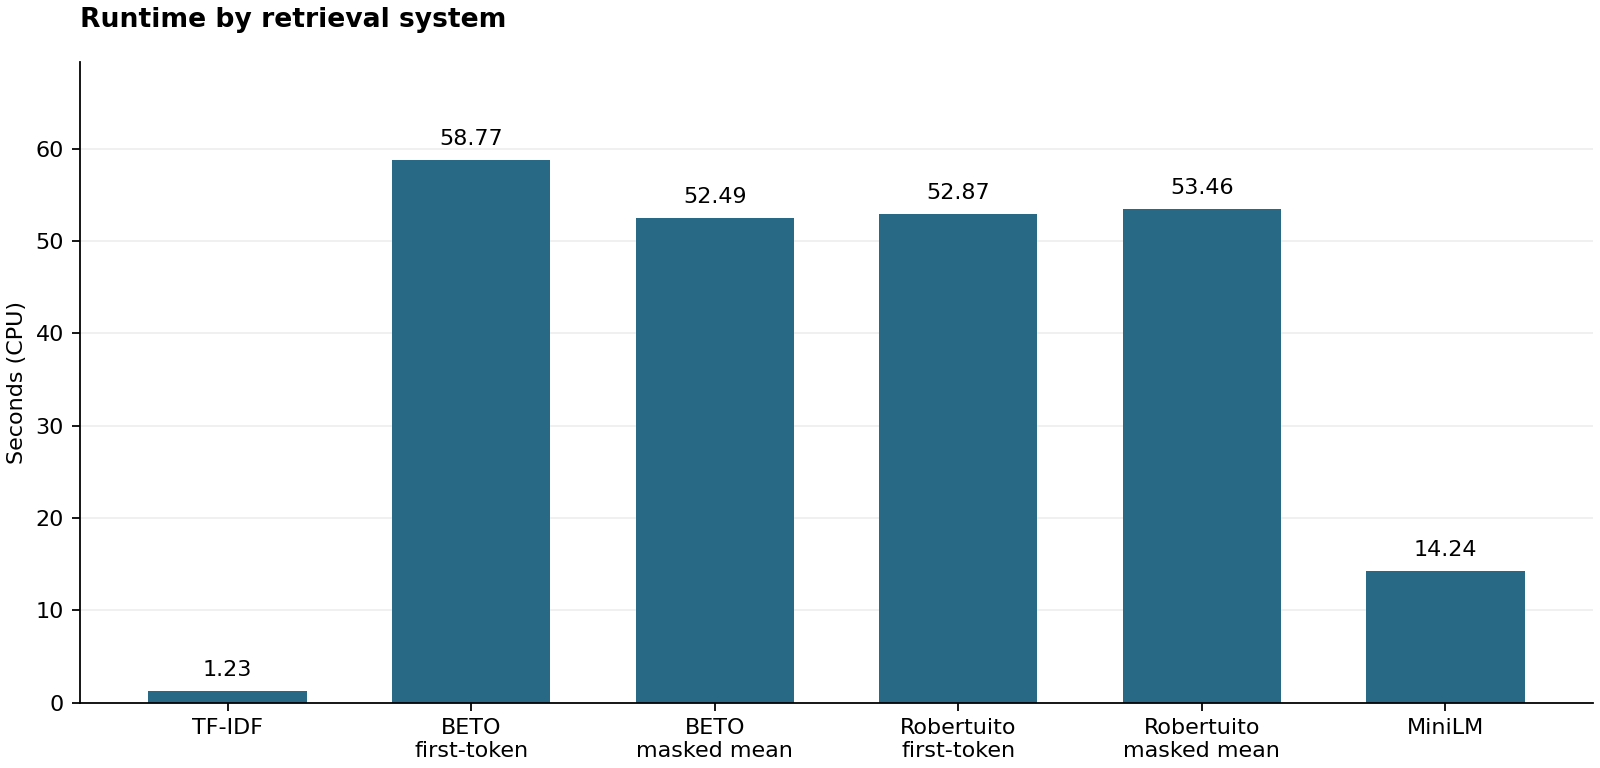

In [6]:
fig = plot_metric(results, 'seconds', 'Runtime by retrieval system', 'Seconds (CPU)', upper=None)
display(fig)
import matplotlib.pyplot as plt
plt.close(fig)


## 9. Interpretation
Robertuito masked mean has the highest aggregate metrics **on this test set**. MiniLM is close in quality and took 14.24 s versus 53.46 s in this CPU run. Masked mean substantially exceeds first-token pooling within both original encoders; TF-IDF remains a fast lexical baseline. Cross-model differences cannot be attributed solely to pooling: training data, architecture details and tokenization also differ. Raw cosine magnitudes are not compared, and no statistical significance or universal superiority is claimed.

## 10. Limitations
The evaluation contains only 15 manually selected information needs and 43 positive judgments, covering 648 pooled query-document pairs. Queries were informed by corpus inspection, but selected before model outputs. Judgments use headline meaning, not ESG metadata. Documents outside each query pool remain unjudged. MRR is restricted to 10; full-corpus recall and unrestricted MRR are unsupported. Some queries have fewer than five positives, limiting their attainable Precision@5. Human ambiguity, title deduplication, truncation to 128 tokens, and the absence of tweet-specific Robertuito preprocessing constrain interpretation. Runtime includes model construction/loading, corpus encoding, query retrieval and scoring; cached CPU wall time is not a controlled latency benchmark.

## 11. Conclusions
This experiment demonstrates the importance of encoder consistency and a frozen human evaluation. Mean pooling improves aggregate metrics within both tested base encoders here; it is not a universal guarantee. Robertuito mean leads this set, MiniLM offers a stronger quality/runtime balance than the base-model means in this CPU run, and TF-IDF provides a fast lexical reference. No production capability, significance, or broad language-understanding superiority is claimed. See [full report](../docs/benchmark.md) and [frozen evaluation protocol](../evaluation/README.md).